# Lab: Artificial Neural Network

**BINF 6210/8210 - Machine Learning for Bioinformatics**
___

### Learning objectives
1. Compute a neuron’s weighted sum and activation; implement a vectorized forward pass.
2. Explain why nonlinear hidden layers can represent XOR/XNOR.
3. Compare sigmoid, tanh, and ReLU and recognize saturation/dying ReLU.
4. Implement a gradient update for a sigmoid output neuron.
5. Fit a multilayer perceptron (MLP) to a biomedical dataset without data leakage.
6. Compare an MLP with logistic regression, inspect training curves, and interpret hidden representations cautiously.

**Data:** scikit-learn's built-in Wisconsin Diagnostic Breast Cancer dataset (30 numerical features, 569 samples). This is an educational benchmark, **not** a clinical diagnostic tool.


## 0. Environment and reproducibility
Install if needed: `python -m pip install numpy matplotlib pandas scikit-learn jupyter`.

Run all cells in order. Random seeds improve reproducibility, but optimizer convergence can vary by software version.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay

SEED = 42
np.random.seed(SEED)
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)


Python: 3.14.2 | scikit-learn: 1.9.0


## 1. From a neuron to a network (15 minutes)
For a single neuron: $z=\mathbf{w}^{T}\mathbf{x}+b$, $a=g(z)$.

**Task 1A:** Calculate $z$ and sigmoid output for $\mathbf{x}=[2,-1,0.5]$, $\mathbf{w}=[0.8,-0.4,1.2]$, and $b=-0.3$. Predict whether the output exceeds 0.5 before running the code.

In [2]:
def sigmoid(z):
    z = np.asarray(z)
    return np.where(z >= 0, 1 / (1 + np.exp(-np.maximum(z, 0))),
                    np.exp(np.minimum(z, 0)) / (1 + np.exp(np.minimum(z, 0))))

x = np.array([2.0, -1.0, 0.5])
w = np.array([0.8, -0.4, 1.2])
b = -0.3
z = x @ w + b
print('z =', z, '| sigmoid(z) =', sigmoid(z))
assert np.isclose(z, 2.3)


z = 2.3000000000000003 | sigmoid(z) = 0.9088770389851438


### Vectorized forward propagation
For $m$ samples stored as rows, let $X\in\mathbb{R}^{m\times d}$. A network with $h$ hidden units and one output has:

$Z_1=XW_1+b_1$, $A_1=\operatorname{ReLU}(Z_1)$, $Z_2=A_1W_2+b_2$, $\hat y=\sigma(Z_2)$.

**Task 1B:** Check all array shapes. Change the number of hidden units and verify that output shape remains $(m,1)$.

In [3]:
rng = np.random.default_rng(SEED)
X_demo = rng.normal(size=(5, 3))
W1 = rng.normal(size=(3, 4))
b1 = np.zeros(4)
W2 = rng.normal(size=(4, 1))
b2 = np.zeros(1)

Z1 = X_demo @ W1 + b1
A1 = np.maximum(0, Z1)
Z2 = A1 @ W2 + b2
Yhat = sigmoid(Z2)
for name, arr in [('X', X_demo), ('Z1', Z1), ('A1', A1), ('Z2', Z2), ('Yhat', Yhat)]:
    print(f'{name:5s} shape = {arr.shape}')
assert Yhat.shape == (5, 1)


X     shape = (5, 3)
Z1    shape = (5, 4)
A1    shape = (5, 4)
Z2    shape = (5, 1)
Yhat  shape = (5, 1)


## 2. Logic gates and nonlinear decision boundaries (15 minutes)
The lecture uses AND, OR, and XNOR to illustrate how neurons can be combined.

**Task 2A:** Run the hand-designed sigmoid gates below. Note that outputs approximate Boolean values; they are not exactly 0 or 1.

In [4]:
X_gate = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)
AND = sigmoid(20 * X_gate.sum(axis=1) - 30)
OR  = sigmoid(20 * X_gate.sum(axis=1) - 10)
NOT_X1 = sigmoid(-20 * X_gate[:,0] + 10)
XNOR = sigmoid(20 * AND + 20 * sigmoid(10 - 20 * X_gate.sum(axis=1)) - 10)
print(pd.DataFrame({'x1': X_gate[:,0].astype(int), 'x2': X_gate[:,1].astype(int),
                    'AND': AND.round(3), 'OR': OR.round(3),
                    'NOT x1': NOT_X1.round(3), 'XNOR': XNOR.round(3)}).to_string(index=False))


 x1  x2  AND  OR  NOT x1  XNOR
  0   0  0.0 0.0     1.0   1.0
  0   1  0.0 1.0     1.0   0.0
  1   0  0.0 1.0     0.0   0.0
  1   1  1.0 1.0     0.0   1.0


**Task 2B:** Train a linear logistic model and a nonlinear MLP on XOR. Compare decision boundaries. A linear model cannot perfectly separate XOR; a hidden-layer MLP can learn it. We use repeated noisy examples to make optimization more stable.

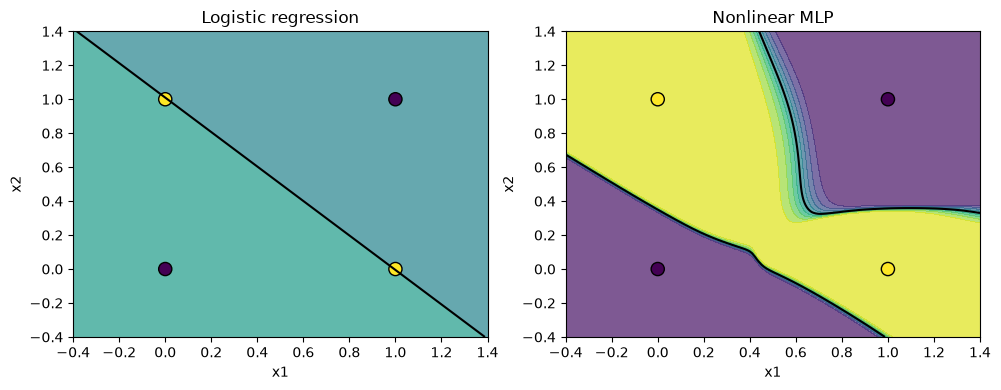

XOR accuracy: linear = 0.535 | MLP = 1.0


In [5]:
rng = np.random.default_rng(17)
X_xor = np.tile(X_gate, (150, 1)) + rng.normal(0, 0.08, size=(600,2))
y_xor = (np.tile(X_gate, (150, 1))[:,0] != np.tile(X_gate, (150, 1))[:,1]).astype(int)
linear = LogisticRegression(C=1e3, max_iter=2000).fit(X_xor, y_xor)
nonlinear = MLPClassifier(hidden_layer_sizes=(8,8), activation='tanh', alpha=0.001,
                          solver='lbfgs', max_iter=2000, random_state=SEED).fit(X_xor, y_xor)
xx, yy = np.meshgrid(np.linspace(-0.4,1.4,170), np.linspace(-0.4,1.4,170))
grid = np.column_stack([xx.ravel(), yy.ravel()])
fig, axes = plt.subplots(1,2,figsize=(10,4))
for ax, model, title in zip(axes,[linear,nonlinear],['Logistic regression','Nonlinear MLP']):
    p = model.predict_proba(grid)[:,1].reshape(xx.shape)
    ax.contourf(xx, yy, p, levels=np.linspace(0,1,11), alpha=.7)
    ax.contour(xx, yy, p, levels=[.5], colors='black')
    ax.scatter(X_gate[:,0],X_gate[:,1],c=[0,1,1,0],edgecolors='black',s=90)
    ax.set(title=title,xlabel='x1',ylabel='x2',xlim=(-.4,1.4),ylim=(-.4,1.4))
plt.tight_layout(); plt.show()
print('XOR accuracy: linear =', round(linear.score(X_xor,y_xor),3),
      '| MLP =', round(nonlinear.score(X_xor,y_xor),3))


## 3. Activation functions (10 minutes)
Compare $\sigma(z)$, $\tanh(z)$, and $\operatorname{ReLU}(z)$. Sigmoid and tanh can saturate at large magnitudes; ReLU has zero derivative for negative inputs (the dying-ReLU issue).

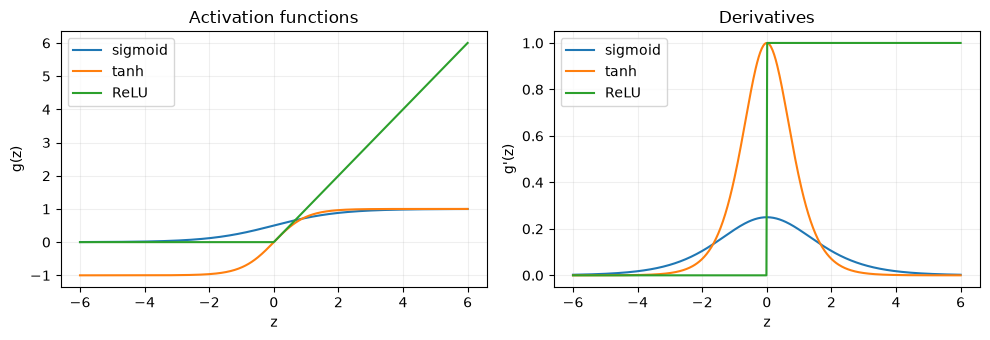

In [6]:
z = np.linspace(-6,6,500)
fig, axes = plt.subplots(1,2,figsize=(10,3.5))
for name, y, deriv in [
    ('sigmoid',sigmoid(z),sigmoid(z)*(1-sigmoid(z))),
    ('tanh',np.tanh(z),1-np.tanh(z)**2),
    ('ReLU',np.maximum(z,0),(z>0).astype(float))]:
    axes[0].plot(z,y,label=name)
    axes[1].plot(z,deriv,label=name)
axes[0].set(title='Activation functions',xlabel='z',ylabel='g(z)')
axes[1].set(title='Derivatives',xlabel='z',ylabel="g'(z)")
for ax in axes: ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()


**Think–pair–share:** Why does stacking several *linear* layers fail to create a nonlinear decision boundary? Why might ReLU be preferred for hidden layers but sigmoid for binary output?

## 4. Loss, gradient descent, and backpropagation (15 minutes)
For binary classification, the average binary cross-entropy loss is

$L=-\frac1m\sum_i[y_i\log(\hat y_i)+(1-y_i)\log(1-\hat y_i)]$.

For a sigmoid output neuron, the gradient simplifies to $\nabla_w L=X^T(\hat y-y)/m$ and $\partial L/\partial b=\operatorname{mean}(\hat y-y)$.

**Task 4A:** Implement full-batch gradient descent for a single sigmoid neuron on AND. This is logistic regression trained from scratch; deeper networks use the chain rule to propagate gradients through hidden layers.

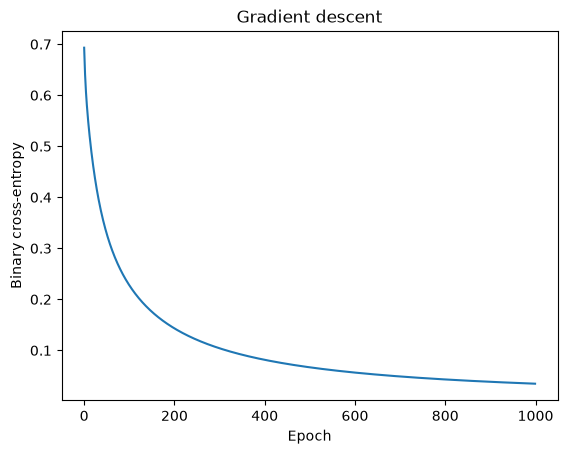

Learned weights: [6.014 6.014] bias: -9.198
AND probabilities: [0.    0.04  0.04  0.944]


In [8]:
X_train_gate = X_gate.copy()
y_and = np.array([0.,0.,0.,1.])
w = np.zeros(2); b = 0.0
lr = 0.5
losses = []
for epoch in range(1000):
    p = sigmoid(X_train_gate @ w + b)
    eps = 1e-12
    loss = -np.mean(y_and*np.log(p+eps)+(1-y_and)*np.log(1-p+eps))
    losses.append(loss)
    error = p-y_and
    dw = X_train_gate.T @ error / len(y_and)
    db = np.mean(error)
    w -= lr*dw
    b -= lr*db
plt.plot(losses); plt.xlabel('Epoch'); plt.ylabel('Binary cross-entropy'); plt.title('Gradient descent'); plt.show()
print('Learned weights:', w.round(3), 'bias:', round(b,3))
print('AND probabilities:', sigmoid(X_train_gate @ w+b).round(3))
assert losses[-1] < losses[0]


**Task 4B (conceptual):** For a two-layer network, describe the order of operations: (1) forward pass, (2) loss, (3) output gradient, (4) hidden-layer gradient via chain rule, (5) parameter update. Which operations depend on the labels?

## 5. Biomedical classification: MLP vs. logistic regression (25 minutes)
We use the Wisconsin Diagnostic Breast Cancer dataset. To avoid confusion, we **recode** the original scikit-learn target so that **1 = malignant** and **0 = benign**. The positive-class probability and ROC AUC then refer to malignancy.

**Important:** Split first, fit the scaler on the training data only, and evaluate on a held-out test set only after model choices are fixed. The demonstration below uses one training/test split and an internal validation split for MLP early stopping.

In [9]:
dataset = load_breast_cancer()
X = dataset.data
y = (dataset.target == 0).astype(int)  # malignant = 1
print('Samples:', X.shape[0], 'features:', X.shape[1])
print('Class counts (0 benign, 1 malignant):', np.bincount(y))
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.25, stratify=y, random_state=SEED)
print('Train:',X_train.shape,'Test:',X_test.shape)


Samples: 569 features: 30
Class counts (0 benign, 1 malignant): [357 212]
Train: (426, 30) Test: (143, 30)


              Model  Test accuracy  Test ROC AUC
Logistic regression          0.965         0.996
        MLP (32,16)          0.979         0.997


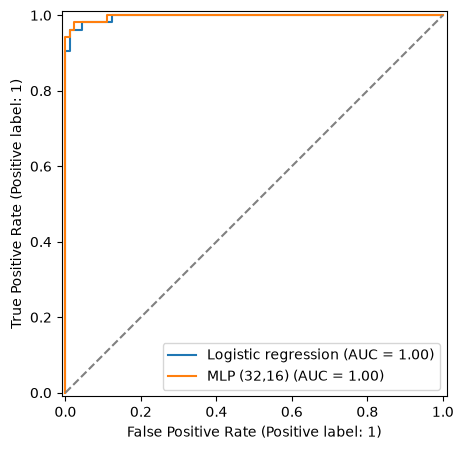

In [11]:
baseline = Pipeline([
    ('scale',StandardScaler()),
    ('model',LogisticRegression(max_iter=2000,random_state=SEED))
])
mlp = Pipeline([
    ('scale',StandardScaler()),
    ('model',MLPClassifier(hidden_layer_sizes=(32,16),activation='relu',
                           alpha=0.01,learning_rate_init=0.001,
                           batch_size=32,early_stopping=True,validation_fraction=0.2,
                           n_iter_no_change=25,max_iter=600,random_state=SEED))
])
for model in [baseline,mlp]:
    model.fit(X_train,y_train)

results=[]
for name,model in [('Logistic regression',baseline),('MLP (32,16)',mlp)]:
    p=model.predict_proba(X_test)[:,1]
    results.append({'Model':name,'Test accuracy':accuracy_score(y_test,p>=.5),
                    'Test ROC AUC':roc_auc_score(y_test,p)})
print(pd.DataFrame(results).round(3).to_string(index=False))
fig,ax=plt.subplots(figsize=(6,5))
for name,model in [('Logistic regression',baseline),('MLP (32,16)',mlp)]:
    RocCurveDisplay.from_estimator(model,X_test,y_test,ax=ax,name=name)
ax.plot([0,1],[0,1],'--',color='gray'); plt.show()


**Task 5A:** Did the MLP outperform logistic regression? Is that guaranteed? Explain why sample size, regularization, and optimization matter.

**Task 5B:** Look at the MLP's loss and validation score over epochs. The `validation_scores_` metric is accuracy for this classifier, not validation loss.

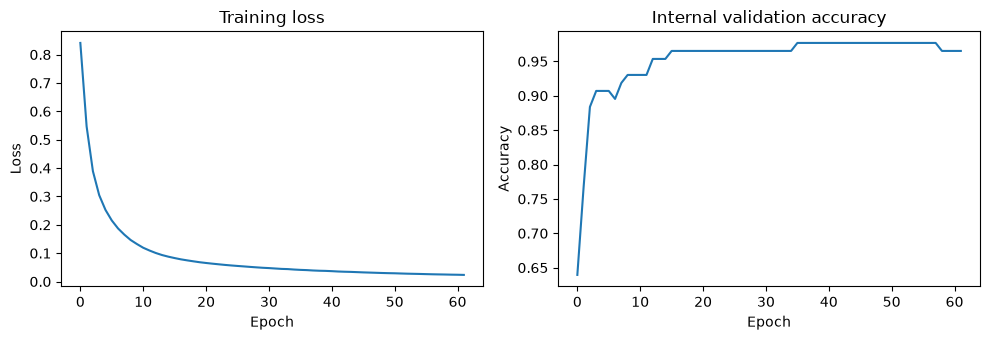

Epochs run: 62 | best internal validation accuracy: 0.9767441860465116


In [12]:
fitted_mlp = mlp.named_steps['model']
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
axes[0].plot(fitted_mlp.loss_curve_)
axes[0].set(title='Training loss',xlabel='Epoch',ylabel='Loss')
if hasattr(fitted_mlp,'validation_scores_') and fitted_mlp.validation_scores_ is not None:
    axes[1].plot(fitted_mlp.validation_scores_)
    axes[1].set(title='Internal validation accuracy',xlabel='Epoch',ylabel='Accuracy')
else:
    axes[1].text(.1,.5,'No validation history',transform=axes[1].transAxes)
plt.tight_layout();plt.show()
print('Epochs run:',fitted_mlp.n_iter_,'| best internal validation accuracy:',fitted_mlp.best_validation_score_)


## 6. Automatic feature learning (10 minutes)
A hidden layer creates a new representation of the input: $H=\operatorname{ReLU}(XW_1+b_1)$. These representations are learned to help predict labels. They are **not automatically identifiable biological pathways**.

**Task 6A:** Inspect the shape of the first hidden layer's learned representation. Compare it with the original feature count.

In [13]:
X_test_scaled = mlp.named_steps['scale'].transform(X_test)
W_first, b_first = fitted_mlp.coefs_[0], fitted_mlp.intercepts_[0]
H_test = np.maximum(0, X_test_scaled @ W_first + b_first)
print('Original feature matrix:',X_test_scaled.shape)
print('First hidden representation:',H_test.shape)
print('First layer weights:',W_first.shape)
assert H_test.shape[1] == 32


Original feature matrix: (143, 30)
First hidden representation: (143, 32)
First layer weights: (30, 32)


**Task 6B (discussion):** Each of the 32 learned features combines the 30 original measurements. Why is it incorrect to label one hidden neuron as a specific biological pathway without further validation?

## 7. Independent exercises / extension (15–30 minutes)
1. **Architecture:** Change the MLP to `(8,)` and `(64,32)` using the same training split. Record test accuracy, ROC AUC, and epoch count. Do not select the final model by repeatedly checking the test set; for rigorous model selection, use validation/CV on the development data.
2. **Regularization:** Compare `alpha=0.0001` and `alpha=1.0`. What changes in training and internal validation behavior?
3. **Activation:** Compare `activation='relu'` and `'tanh'` using the same random state.
4. **Backpropagation:** For a single sigmoid neuron, verify the analytic gradient against a finite-difference approximation.
5. **Bioinformatics:** Propose a gene-expression classification study. Identify the splitting unit (patient vs. sample), preprocessing, baseline model, potential confounders, and a biological interpretation strategy.

**Optional code starter (gradient check):**

In [ ]:
# Optional exercise: fill in the missing code, then remove the comment markers.
# w0 = np.array([0.2, -0.1]); b0 = 0.05; h = 1e-5
# def binary_loss(w, b):
#     p = sigmoid(X_train_gate @ w + b)
#     return -np.mean(y_and*np.log(p+1e-12)+(1-y_and)*np.log(1-p+1e-12))
# analytic = X_train_gate.T @ (sigmoid(X_train_gate @ w0+b0)-y_and)/len(y_and)
# numerical = np.array([ ... for j in range(len(w0)) ])  # central differences
# print(analytic, numerical)


## Exit ticket
Answer briefly:

1. What is the difference between **learned weights** in logistic regression and **learned hidden features** in an MLP?
2. Why do hidden layers need nonlinear activations?
3. Why must standardization be fit only on training data?
4. Why is a good test ROC AUC not proof that the network has discovered meaningful biological mechanisms?

**Instructor note:** This notebook intentionally prioritizes interpretability and CPU-friendly models over deep-learning frameworks. The MLP is a feedforward fully connected neural network; convolutional, recurrent, and transformer models are beyond this introductory lab.